In [ ]:
# ===== Setup =====
import json
import sys
sys.path.append("../src")

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.base import clone
from sklearn.metrics import (accuracy_score, average_precision_score, precision_score, confusion_matrix, recall_score, f1_score, roc_auc_score)

from spark_core import *

TABLES = Path("../outputs/tables")
FIGURES = Path("../outputs/figures")
TABLES.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

MODEL_NAMES = ["Decision Tree", "Random Forest", "KNN", "Logistic regression", "SVM", "XGBoost"]
MAIN_MODEL = "Random Forest"
STAGE_LABEL = {"stage1": "Stage 1", "stage2": "Stage 2"}

# ===== Data =====
dev = pd.read_csv("../data/processed/v2_math_dev.csv")
holdout = pd.read_csv("../data/processed/v2_math_holdout_do_not_open.csv")
por_full, por_clean = load_portuguese()

y_dev = dev["risk"]
is_high_dev = (y_dev == "High").astype(int).values

# ===== Frozen bundles and the tuned settings saved earlier =====
bundles = {name: load_bundle(f"../models/v2_bundle_{name.replace(' ', '_')}.joblib")
           for name in MODEL_NAMES}

with open(TABLES / "v2_best_params.json") as f:
    best_params = json.load(f)["best_params"]
with open(TABLES / "v2_extra_params.json") as f:
    extra_params = json.load(f)
all_params = {stage: {**best_params[stage], **extra_params[stage]} for stage in STAGE_COLS}

print("Development:", len(dev), " Hold out:", len(holdout),
      " Portuguese without overlap:", len(por_clean), " full:", len(por_full))
print({name: {s: round(t, 3) for s, t in b["thresholds"].items()} for name, b in bundles.items()})

import warnings
warnings.filterwarnings("ignore", category=FutureWarning, message=".*probability.*")

Development: 316  Hold out: 79  Portuguese without overlap: 275  full: 649
{'Decision Tree': {'stage1': 0.484, 'stage2': 0.598}, 'Random Forest': {'stage1': 0.496, 'stage2': 0.562}, 'KNN': {'stage1': 0.424, 'stage2': 0.543}, 'Logistic regression': {'stage1': 0.399, 'stage2': 0.562}, 'SVM': {'stage1': 0.368, 'stage2': 0.467}, 'XGBoost': {'stage1': 0.429, 'stage2': 0.481}}


Feature set comparison, Random Forest


,feature_set,recall_high,recall_high_sd,recall_macro,f1_macro,accuracy
0,"G1, G2 and all others",0.884,0.052,0.876,0.874,0.865
1,"G1 and all others, no G2",0.737,0.076,0.734,0.730,0.719
2,G1 and G2 only,0.885,0.083,0.874,0.872,0.865
3,No grades,0.478,0.072,0.488,0.485,0.488



Models and balancing strategies, all features


,dataset,model,balancing,recall_high,recall_high_sd,recall_macro,f1_macro,accuracy
0,main,Random Forest,class_weight,0.884,0.052,0.876,0.874,0.865
1,main,Random Forest,smote,0.862,0.068,0.876,0.876,0.867
2,main,Random Forest,none,0.856,0.053,0.876,0.877,0.868
3,main,Decision Tree,smote,0.782,0.079,0.815,0.814,0.804
4,main,Decision Tree,none,0.776,0.074,0.803,0.801,0.790
5,main,Decision Tree,class_weight,0.763,0.075,0.798,0.800,0.789
6,main,KNN,smote,0.677,0.108,0.717,0.699,0.689
7,main,KNN,none,0.616,0.101,0.729,0.730,0.720



Same comparison without absences


,dataset,model,balancing,recall_high,recall_high_sd,recall_macro,f1_macro,accuracy
0,no absences,Random Forest,class_weight,0.884,0.050,0.883,0.882,0.873
1,no absences,Random Forest,smote,0.872,0.065,0.884,0.884,0.876
2,no absences,Random Forest,none,0.852,0.064,0.875,0.877,0.868
3,no absences,Decision Tree,none,0.798,0.082,0.815,0.815,0.807
4,no absences,Decision Tree,class_weight,0.773,0.083,0.811,0.810,0.801
5,no absences,Decision Tree,smote,0.769,0.087,0.805,0.804,0.794
6,no absences,KNN,smote,0.680,0.086,0.714,0.694,0.683
7,no absences,KNN,none,0.597,0.089,0.711,0.712,0.700



Rule baselines on the Mathematics file


,baseline,recall_high,recall_macro,f1_macro,accuracy
0,G2 carried forward,0.938,0.882,0.884,0.878
1,G1 carried forward,0.800,0.744,0.743,0.734



Pooled experiments, version 1


,stage,approach,subject,recall_high,precision_high,f1_macro,accuracy,high_predicted_low,net_vs_rule
0,"Stage 1, G1 only","Rule, carry grade forward",All,0.826,0.644,0.742,0.740,0.000,0.000
1,"Stage 1, G1 only","Rule, carry grade forward",Mathematics,0.798,0.716,0.728,0.718,0.000,0.000
2,"Stage 1, G1 only","Rule, carry grade forward",Portuguese,0.862,0.575,0.742,0.753,0.000,0.000
3,"Stage 1, G1 only",Logistic regression,All,0.777,0.673,0.730,0.727,0.000,-11.000
4,"Stage 1, G1 only",Logistic regression,Mathematics,0.814,0.693,0.681,0.676,0.000,-13.333
5,"Stage 1, G1 only",Logistic regression,Portuguese,0.729,0.648,0.744,0.757,0.000,2.333
6,"Stage 1, G1 only",Random Forest,All,0.864,0.639,0.736,0.730,0.000,-8.333
7,"Stage 1, G1 only",Random Forest,Mathematics,0.962,0.654,0.697,0.698,0.000,-6.333
8,"Stage 1, G1 only",Random Forest,Portuguese,0.737,0.618,0.736,0.749,0.000,-2.000
9,"Stage 1, G1 only",Gradient boosting,All,0.719,0.707,0.743,0.748,0.000,7.000


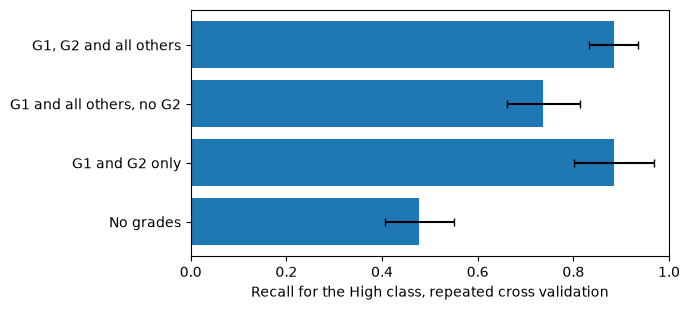

In [43]:
# ===== Version 1 exploratory tables, read only =====
v1_files = {
    "Feature set comparison, Random Forest": "cv_feature_sets.csv",
    "Models and balancing strategies, all features": "cv_main.csv",
    "Same comparison without absences": "cv_no_absences.csv",
    "Rule baselines on the Mathematics file": "baselines.csv",
    "Pooled experiments, version 1": "pooled_experiments.csv",
}

for title, name in v1_files.items():
    print(title)
    path = TABLES / name
    if path.exists():
        display(pd.read_csv(path).round(3))
    else:
        print(f"  missing {name}")
    print()

# ===== Chart of the feature set comparison =====
fs_path = TABLES / "cv_feature_sets.csv"
if fs_path.exists():
    fs = pd.read_csv(fs_path)
    fig, ax = plt.subplots(figsize=(7, 3.2))
    ax.barh(fs["feature_set"], fs["recall_high"], xerr=fs["recall_high_sd"], capsize=3)
    ax.invert_yaxis()
    ax.set_xlabel("Recall for the High class, repeated cross validation")
    ax.set_xlim(0, 1)
    plt.tight_layout()
    plt.savefig(FIGURES / "v1_feature_sets.png", dpi=200)
    plt.show()

In [44]:
# ===== Development results on fresh folds, six models and the rules =====
rows = []
for stage, cols in STAGE_COLS.items():
    for name in MODEL_NAMES:
        pipe = make_pipeline(name, **all_params[stage][name])
        runs = oof_high_proba(pipe, dev[cols], y_dev, n_repeats=5)
        ap = [average_precision_score(is_high_dev, r) for r in runs]
        par = [precision_at_recall(is_high_dev, r) for r in runs]
        rows.append({"stage": stage, "model": name,
                     "avg_precision": np.mean(ap), "avg_precision_sd": np.std(ap),
                     "precision_at_90_recall": np.mean(par)})

for stage, col in [("stage1", "G1"), ("stage2", "G2")]:
    score = -dev[col].values
    rows.append({"stage": stage, "model": f"Rule, {col} carried forward",
                 "avg_precision": average_precision_score(is_high_dev, score),
                 "avg_precision_sd": 0.0,
                 "precision_at_90_recall": precision_at_recall(is_high_dev, score)})

dev_six = pd.DataFrame(rows).round(3)
dev_six.to_csv(TABLES / "v2_dev_six_models.csv", index=False)
dev_six.sort_values(["stage", "avg_precision"], ascending=[True, False])

,stage,model,avg_precision,avg_precision_sd,precision_at_90_recall
3,stage1,Logistic regression,0.823,0.004,0.668
12,stage1,"Rule, G1 carried forward",0.810,0.000,0.652
0,stage1,Decision Tree,0.798,0.006,0.659
2,stage1,KNN,0.797,0.007,0.659
5,stage1,XGBoost,0.797,0.001,0.659
1,stage1,Random Forest,0.793,0.005,0.660
4,stage1,SVM,0.715,0.028,0.461
7,stage2,Random Forest,0.949,0.003,0.852
11,stage2,XGBoost,0.949,0.002,0.854
9,stage2,Logistic regression,0.946,0.000,0.846


In [45]:
# ===== Paired bootstrap, each tuned model against the rule =====
rng = np.random.default_rng(RANDOM_STATE)

def bootstrap_gap(score_a, score_b, n_boot=1000):
    gaps = []
    n = len(is_high_dev)
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        if is_high_dev[idx].sum() < 5:
            continue
        gaps.append(average_precision_score(is_high_dev[idx], score_a[idx])
                    - average_precision_score(is_high_dev[idx], score_b[idx]))
    return np.percentile(gaps, [2.5, 50, 97.5])

rows = []
for stage, col in [("stage1", "G1"), ("stage2", "G2")]:
    rule_score = -dev[col].values
    for name in MODEL_NAMES:
        pipe = make_pipeline(name, **all_params[stage][name])
        runs = oof_high_proba(pipe, dev[STAGE_COLS[stage]], y_dev, n_repeats=5)
        low, mid, high = bootstrap_gap(np.mean(runs, axis=0), rule_score)
        rows.append({"stage": stage, "model": name,
                     "median_gap": mid, "ci_low": low, "ci_high": high})

bootstrap_table = pd.DataFrame(rows).round(3)
bootstrap_table.to_csv(TABLES / "v2_bootstrap_gap.csv", index=False)
bootstrap_table

,stage,model,median_gap,ci_low,ci_high
0,stage1,Decision Tree,-0.020,-0.050,0.011
1,stage1,Random Forest,-0.025,-0.054,-0.000
2,stage1,KNN,-0.018,-0.050,0.009
3,stage1,Logistic regression,0.008,-0.008,0.022
4,stage1,SVM,-0.056,-0.110,-0.005
5,stage1,XGBoost,-0.030,-0.062,-0.001
6,stage2,Decision Tree,0.012,0.002,0.024
7,stage2,Random Forest,0.020,0.006,0.037
8,stage2,KNN,0.014,0.004,0.027
9,stage2,Logistic regression,0.016,0.007,0.028


In [46]:
# ===== Operating points on development data, from the frozen bundles =====
rows = []
for name, bundle in bundles.items():
    for stage, cols in STAGE_COLS.items():
        pipe = clone(bundle["models"][stage])
        runs = oof_high_proba(pipe, dev[cols], y_dev, n_repeats=3)
        flagged = [r >= bundle["thresholds"][stage] for r in runs]
        rows.append({
            "model": name, "stage": stage,
            "threshold": bundle["thresholds"][stage],
            "share_flagged": np.mean([f.mean() for f in flagged]),
            "recall": np.mean([is_high_dev[f].sum() / is_high_dev.sum() for f in flagged]),
            "precision": np.mean([is_high_dev[f].mean() for f in flagged]),
        })

op = pd.DataFrame(rows).round(3)
op.to_csv(TABLES / "v2_dev_operating_points_six.csv", index=False)
op

,model,stage,threshold,share_flagged,recall,precision
0,Decision Tree,stage1,0.484,0.445,0.901,0.666
1,Decision Tree,stage2,0.598,0.351,0.904,0.847
2,Random Forest,stage1,0.496,0.445,0.901,0.666
3,Random Forest,stage2,0.562,0.350,0.904,0.849
4,KNN,stage1,0.424,0.458,0.920,0.661
5,KNN,stage2,0.543,0.362,0.923,0.840
6,Logistic regression,stage1,0.399,0.440,0.901,0.674
7,Logistic regression,stage2,0.562,0.351,0.904,0.847
8,SVM,stage1,0.368,0.659,0.901,0.450
9,SVM,stage2,0.467,0.349,0.901,0.849


In [57]:
# ===== Interval and detailed evaluation helpers =====
def wilson(k, n, z=1.96):
    p = k / n
    denom = 1 + z ** 2 / n
    centre = (p + z ** 2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / denom
    return centre - half, centre + half


def detailed_rows(data, label):
    y_true = data["risk"].values
    n_high = int((y_true == "High").sum())
    rows = []

    def add(approach, stage, pred, proba=None):
        caught = int(((y_true == "High") & (pred == "High")).sum())
        flagged = int((pred == "High").sum())
        low, high = wilson(caught, n_high)
        rows.append({
            "test set": label, "approach": approach, "stage": stage,
            "students": len(data), "high_students": n_high, "high_caught": caught,
            "high_to_medium": int(((y_true == "High") & (pred == "Medium")).sum()),
            "high_to_low": int(((y_true == "High") & (pred == "Low")).sum()),
            "flagged_high": flagged,
            "false_alarms": int(((y_true != "High") & (pred == "High")).sum()),
            "recall_high": caught / n_high, "recall_ci_low": low, "recall_ci_high": high,
            "precision_high": caught / max(flagged, 1),
            "accuracy": accuracy_score(y_true, pred),
            "f1_macro": f1_score(y_true, pred, labels=RISK_ORDER, average="macro", zero_division=0),
            "roc_auc_ovr": (roc_auc_score(y_true, proba, multi_class="ovr", labels=sorted(RISK_ORDER))
                            if proba is not None else np.nan),
        })

    for stage, col in [("stage1", "G1"), ("stage2", "G2")]:
        add(f"Rule, {col} carried forward", stage, data[col].apply(assign_risk).values)

    for name, bundle in bundles.items():
        for stage, cols in STAGE_COLS.items():
            pred = score_students(data[cols], bundle)["risk"].values
            add(name, stage, pred, stage_probabilities(bundle, data, stage))

    return rows


# ===== Run on the three test sets =====
test_sets = {
    "Mathematics hold out": holdout,
    "Portuguese, no overlap": por_clean,
    "Portuguese, full file": por_full,
}

detailed = pd.DataFrame([row for label, data in test_sets.items()
                         for row in detailed_rows(data, label)])
detailed.round(3).to_csv(TABLES / "v2_final_detailed_results.csv", index=False)
print("Saved", len(detailed), "rows")

Saved 42 rows


In [59]:
# ===== Interval and detailed evaluation helpers =====
def wilson(k, n, z=1.96):
    p = k / n
    denom = 1 + z ** 2 / n
    centre = (p + z ** 2 / (2 * n)) / denom
    half = z * np.sqrt(
        p * (1 - p) / n + z ** 2 / (4 * n ** 2)
    ) / denom

    return centre - half, centre + half


def detailed_rows(data, label):
    y_true = data["risk"].values
    n_high = int((y_true == "High").sum())
    rows = []

    def add(approach, stage, pred, proba=None):

        # ===== High-risk detection metrics =====
        caught = int(
            ((y_true == "High") & (pred == "High")).sum()
        )

        flagged = int(
            (pred == "High").sum()
        )

        low, high = wilson(caught, n_high)

        # ===== Overall classification metrics =====
        accuracy = accuracy_score(
            y_true,
            pred
        )

        precision_macro = precision_score(
            y_true,
            pred,
            labels=RISK_ORDER,
            average="macro",
            zero_division=0
        )

        recall_macro = recall_score(
            y_true,
            pred,
            labels=RISK_ORDER,
            average="macro",
            zero_division=0
        )

        f1_macro = f1_score(
            y_true,
            pred,
            labels=RISK_ORDER,
            average="macro",
            zero_division=0
        )

        # ===== ROC-AUC =====
        roc_auc = (
            roc_auc_score(
                y_true,
                proba,
                multi_class="ovr",
                labels=sorted(RISK_ORDER)
            )
            if proba is not None
            else np.nan
        )

        rows.append({
            # Identification
            "test set": label,
            "approach": approach,
            "stage": stage,

            # Dataset information
            "students": len(data),
            "high_students": n_high,

            # High-risk detection
            "high_caught": caught,
            "high_to_medium": int(
                ((y_true == "High") & (pred == "Medium")).sum()
            ),
            "high_to_low": int(
                ((y_true == "High") & (pred == "Low")).sum()
            ),
            "flagged_high": flagged,
            "false_alarms": int(
                ((y_true != "High") & (pred == "High")).sum()
            ),

            # High-risk metrics
            "recall_high": caught / n_high,
            "recall_ci_low": low,
            "recall_ci_high": high,
            "precision_high": caught / max(flagged, 1),

            # Overall model evaluation
            "accuracy": accuracy,
            "precision_macro": precision_macro,
            "recall_macro": recall_macro,
            "f1_macro": f1_macro,

            # ROC-AUC
            "roc_auc_ovr": roc_auc,
        })

    # ========================================================
    # BASELINE RULE
    # ========================================================

    for stage, col in [
        ("stage1", "G1"),
        ("stage2", "G2")
    ]:

        add(
            f"Rule, {col} carried forward",
            stage,
            data[col].apply(assign_risk).values
        )

    # ========================================================
    # MACHINE LEARNING MODELS
    # ========================================================

    for name, bundle in bundles.items():

        for stage, cols in STAGE_COLS.items():

            pred = score_students(
                data[cols],
                bundle
            )["risk"].values

            add(
                name,
                stage,
                pred,
                stage_probabilities(
                    bundle,
                    data,
                    stage
                )
            )

    return rows


# ===== Run on the three test sets =====

test_sets = {
    "Mathematics hold out": holdout,
    "Portuguese, no overlap": por_clean,
    "Portuguese, full file": por_full,
}


# ============================================================
# CREATE COMPLETE RESULTS TABLE
# ============================================================

detailed = pd.DataFrame(
    [
        row
        for label, data in test_sets.items()
        for row in detailed_rows(data, label)
    ]
)


# ============================================================
# ROUND NUMERICAL VALUES
# ============================================================

detailed = detailed.round(3)


# ============================================================
# SAVE COMPLETE RESULTS
# ============================================================

output_file = TABLES / "v2_final_detailed_results2.csv"

detailed.to_csv(
    output_file,
    index=False
)

print("Saved", len(detailed), "rows to", output_file)


# ============================================================
# PRINT THE MAIN MODEL METRIC TABLE
# ============================================================

metric_columns = [
    "test set",
    "stage",
    "approach",
    "accuracy",
    "precision_macro",
    "recall_macro",
    "f1_macro",
    "precision_high",
    "recall_high",
    "roc_auc_ovr",
]

metric_table = detailed[metric_columns]

print("\n")
print("=" * 100)
print("FULL MODEL METRIC TABLE")
print("=" * 100)

print(
    metric_table.to_string(index=False)
)


# ============================================================
# PRINT EACH TEST SET + STAGE SEPARATELY
# ============================================================

for test_set in test_sets.keys():

    for stage in ["stage1", "stage2"]:

        table = detailed[
            (detailed["test set"] == test_set) &
            (detailed["stage"] == stage)
        ][
            [
                "approach",
                "accuracy",
                "precision_macro",
                "recall_macro",
                "f1_macro",
                "precision_high",
                "recall_high",
                "roc_auc_ovr",
            ]
        ]

        print("\n")
        print("=" * 100)
        print(f"{test_set} - {stage}")
        print("=" * 100)

        print(
            table.to_string(index=False)
        )

Saved 42 rows to ..\outputs\tables\v2_final_detailed_results2.csv


FULL MODEL METRIC TABLE
              test set  stage                 approach  accuracy  precision_macro  recall_macro  f1_macro  precision_high  recall_high  roc_auc_ovr
  Mathematics hold out stage1 Rule, G1 carried forward     0.747            0.770         0.745     0.754           0.750        0.808          NaN
  Mathematics hold out stage2 Rule, G2 carried forward     0.861            0.871         0.870     0.869           0.800        0.923          NaN
  Mathematics hold out stage1            Decision Tree     0.696            0.729         0.713     0.705           0.632        0.923        0.890
  Mathematics hold out stage2            Decision Tree     0.861            0.871         0.870     0.869           0.800        0.923        0.959
  Mathematics hold out stage1            Random Forest     0.696            0.729         0.713     0.705           0.632        0.923        0.894
  Mathematics hold o

In [48]:
# ===== Test tables for the report =====
show = ["approach", "high_students", "high_caught", "high_to_medium", "high_to_low",
        "flagged_high", "false_alarms", "recall_high", "recall_ci_low", "recall_ci_high",
        "precision_high", "accuracy", "f1_macro", "roc_auc_ovr"]

for label in test_sets:
    for stage in STAGE_COLS:
        part = detailed[(detailed["test set"] == label) & (detailed["stage"] == stage)]
        print(f"{label}, {STAGE_LABEL[stage]}")
        display(part[show].round(3).reset_index(drop=True))
        print()

Mathematics hold out, Stage 1


,approach,high_students,high_caught,high_to_medium,high_to_low,flagged_high,false_alarms,recall_high,recall_ci_low,recall_ci_high,precision_high,accuracy,f1_macro,roc_auc_ovr
0,"Rule, G1 carried forward",26,21,5,0,28,7,0.808,0.621,0.915,0.750,0.747,0.754,NaN
1,Decision Tree,26,24,2,0,38,14,0.923,0.759,0.979,0.632,0.696,0.705,0.890
2,Random Forest,26,24,2,0,38,14,0.923,0.759,0.979,0.632,0.696,0.705,0.894
3,KNN,26,21,5,0,28,7,0.808,0.621,0.915,0.750,0.747,0.754,0.889
4,Logistic regression,26,21,5,0,28,7,0.808,0.621,0.915,0.750,0.747,0.754,0.898
5,SVM,26,24,2,0,38,14,0.923,0.759,0.979,0.632,0.544,0.421,0.684
6,XGBoost,26,24,2,0,38,14,0.923,0.759,0.979,0.632,0.696,0.705,0.890



Mathematics hold out, Stage 2


,approach,high_students,high_caught,high_to_medium,high_to_low,flagged_high,false_alarms,recall_high,recall_ci_low,recall_ci_high,precision_high,accuracy,f1_macro,roc_auc_ovr
0,"Rule, G2 carried forward",26,24,2,0,30,6,0.923,0.759,0.979,0.800,0.861,0.869,NaN
1,Decision Tree,26,24,2,0,30,6,0.923,0.759,0.979,0.800,0.861,0.869,0.959
2,Random Forest,26,24,2,0,29,5,0.923,0.759,0.979,0.828,0.861,0.866,0.962
3,KNN,26,23,3,0,27,4,0.885,0.710,0.960,0.852,0.848,0.853,0.964
4,Logistic regression,26,23,3,0,27,4,0.885,0.710,0.960,0.852,0.861,0.866,0.966
5,SVM,26,24,2,0,30,6,0.923,0.759,0.979,0.800,0.861,0.869,0.962
6,XGBoost,26,24,2,0,30,6,0.923,0.759,0.979,0.800,0.861,0.869,0.967



Portuguese, no overlap, Stage 1


,approach,high_students,high_caught,high_to_medium,high_to_low,flagged_high,false_alarms,recall_high,recall_ci_low,recall_ci_high,precision_high,accuracy,f1_macro,roc_auc_ovr
0,"Rule, G1 carried forward",70,63,7,0,105,42,0.9,0.808,0.951,0.600,0.695,0.690,NaN
1,Decision Tree,70,70,0,0,150,80,1.0,0.948,1.000,0.467,0.582,0.597,0.859
2,Random Forest,70,70,0,0,150,80,1.0,0.948,1.000,0.467,0.582,0.597,0.881
3,KNN,70,63,7,0,105,42,0.9,0.808,0.951,0.600,0.695,0.690,0.858
4,Logistic regression,70,63,7,0,105,42,0.9,0.808,0.951,0.600,0.709,0.717,0.886
5,SVM,70,70,0,0,150,80,1.0,0.948,1.000,0.467,0.476,0.365,0.696
6,XGBoost,70,70,0,0,150,80,1.0,0.948,1.000,0.467,0.582,0.597,0.858


... (2 outputs left out)


Portuguese, full file, Stage 1


,approach,high_students,high_caught,high_to_medium,high_to_low,flagged_high,false_alarms,recall_high,recall_ci_low,recall_ci_high,precision_high,accuracy,f1_macro,roc_auc_ovr
0,"Rule, G1 carried forward",100,88,12,0,157,69,0.88,0.802,0.930,0.561,0.752,0.741,NaN
1,Decision Tree,100,98,2,0,252,154,0.98,0.930,0.994,0.389,0.641,0.647,0.881
2,Random Forest,100,98,2,0,252,154,0.98,0.930,0.994,0.389,0.641,0.647,0.898
3,KNN,100,88,12,0,157,69,0.88,0.802,0.930,0.561,0.752,0.741,0.880
4,Logistic regression,100,88,12,0,157,69,0.88,0.802,0.930,0.561,0.730,0.726,0.902
5,SVM,100,98,2,0,252,154,0.98,0.930,0.994,0.389,0.465,0.366,0.682
6,XGBoost,100,98,2,0,252,154,0.98,0.930,0.994,0.389,0.641,0.647,0.880



Portuguese, full file, Stage 2


,approach,high_students,high_caught,high_to_medium,high_to_low,flagged_high,false_alarms,recall_high,recall_ci_low,recall_ci_high,precision_high,accuracy,f1_macro,roc_auc_ovr
0,"Rule, G2 carried forward",100,89,11,0,145,56,0.89,0.814,0.937,0.614,0.823,0.808,NaN
1,Decision Tree,100,89,11,0,145,56,0.89,0.814,0.937,0.614,0.823,0.808,0.935
2,Random Forest,100,82,18,0,131,49,0.82,0.733,0.883,0.626,0.821,0.803,0.942
3,KNN,100,88,12,0,134,46,0.88,0.802,0.930,0.657,0.835,0.821,0.941
4,Logistic regression,100,88,12,0,133,45,0.88,0.802,0.930,0.662,0.832,0.819,0.953
5,SVM,100,89,11,0,145,56,0.89,0.814,0.937,0.614,0.823,0.808,0.949
6,XGBoost,100,85,15,0,156,71,0.85,0.767,0.907,0.545,0.794,0.778,0.940


In [61]:
# ===== Compact test tables for screenshots/report =====

# Main model evaluation metrics
metric_show = [
    "approach",
    "accuracy",
    "precision_macro",
    "recall_macro",
    "f1_macro",
    "roc_auc_ovr",
]

# High-risk detection metrics
risk_show = [
    "approach",
    "high_students",
    "high_caught",
    "flagged_high",
    "false_alarms",
    "precision_high",
    "recall_high",
]


# ------------------------------------------------------------
# Function to display a compact table
# ------------------------------------------------------------

def display_compact_table(part, columns):
    table = part[columns].round(3).reset_index(drop=True)

    # Shorter column names for screenshot/report
    table = table.rename(columns={
        "approach": "Model",
        "accuracy": "Accuracy",
        "precision_macro": "Macro Prec.",
        "recall_macro": "Macro Recall",
        "f1_macro": "Macro F1",
        "roc_auc_ovr": "ROC-AUC",

        "high_students": "High Students",
        "high_caught": "High Caught",
        "flagged_high": "Flagged High",
        "false_alarms": "False Alarms",
        "precision_high": "High Prec.",
        "recall_high": "High Recall",
    })

    # Display with pandas styling
    styled = (
        table.style
        .hide(axis="index")
        .set_properties(**{
            "font-size": "10pt",
            "text-align": "center",
            "padding": "4px"
        })
        .set_table_styles([
            {
                "selector": "th",
                "props": [
                    ("font-size", "10pt"),
                    ("text-align", "center"),
                    ("padding", "4px"),
                    ("white-space", "nowrap")
                ]
            },
            {
                "selector": "td:first-child",
                "props": [
                    ("text-align", "left"),
                    ("white-space", "nowrap")
                ]
            }
        ])
    )

    display(styled)


# ============================================================
# MAIN MODEL METRIC TABLES
# ============================================================

print("\n==============================")
print("MODEL PERFORMANCE METRICS")
print("==============================")

for label in test_sets:

    for stage in STAGE_COLS:

        part = detailed[
            (detailed["test set"] == label) &
            (detailed["stage"] == stage)
        ]

        print(f"\n{label} — {STAGE_LABEL[stage]}")

        display_compact_table(
            part,
            metric_show
        )


# ============================================================
# HIGH-RISK DETECTION TABLES
# ============================================================

print("\n==============================")
print("HIGH-RISK DETECTION METRICS")
print("==============================")

for label in test_sets:

    for stage in STAGE_COLS:

        part = detailed[
            (detailed["test set"] == label) &
            (detailed["stage"] == stage)
        ]

        print(f"\n{label} — {STAGE_LABEL[stage]}")

        display_compact_table(
            part,
            risk_show
        )


MODEL PERFORMANCE METRICS

Mathematics hold out — Stage 1


Model,Accuracy,Macro Prec.,Macro Recall,Macro F1,ROC-AUC
"Rule, G1 carried forward",0.747000,0.770000,0.745000,0.754000,nan
Decision Tree,0.696000,0.729000,0.713000,0.705000,0.890000
Random Forest,0.696000,0.729000,0.713000,0.705000,0.894000
KNN,0.747000,0.770000,0.745000,0.754000,0.889000
Logistic regression,0.747000,0.747000,0.771000,0.754000,0.898000
SVM,0.544000,0.365000,0.500000,0.421000,0.684000
XGBoost,0.696000,0.729000,0.713000,0.705000,0.890000



Mathematics hold out — Stage 2


Model,Accuracy,Macro Prec.,Macro Recall,Macro F1,ROC-AUC
"Rule, G2 carried forward",0.861000,0.871000,0.870000,0.869000,nan
Decision Tree,0.861000,0.871000,0.870000,0.869000,0.959000
Random Forest,0.861000,0.865000,0.870000,0.866000,0.962000
KNN,0.848000,0.855000,0.851000,0.853000,0.964000
Logistic regression,0.861000,0.865000,0.868000,0.866000,0.966000
SVM,0.861000,0.871000,0.870000,0.869000,0.962000
XGBoost,0.861000,0.871000,0.870000,0.869000,0.967000



Portuguese, no overlap — Stage 1


Model,Accuracy,Macro Prec.,Macro Recall,Macro F1,ROC-AUC
"Rule, G1 carried forward",0.695000,0.730000,0.699000,0.690000,nan
Decision Tree,0.582000,0.663000,0.643000,0.597000,0.859000
Random Forest,0.582000,0.663000,0.643000,0.597000,0.881000
KNN,0.695000,0.730000,0.699000,0.690000,0.858000
Logistic regression,0.709000,0.718000,0.743000,0.717000,0.886000
SVM,0.476000,0.318000,0.478000,0.365000,0.696000
XGBoost,0.582000,0.663000,0.643000,0.597000,0.858000


... (14 outputs left out)


Portuguese, full file — Stage 1


Model,High Students,High Caught,Flagged High,False Alarms,High Prec.,High Recall
"Rule, G1 carried forward",100,88,157,69,0.561000,0.880000
Decision Tree,100,98,252,154,0.389000,0.980000
Random Forest,100,98,252,154,0.389000,0.980000
KNN,100,88,157,69,0.561000,0.880000
Logistic regression,100,88,157,69,0.561000,0.880000
SVM,100,98,252,154,0.389000,0.980000
XGBoost,100,98,252,154,0.389000,0.980000



Portuguese, full file — Stage 2


Model,High Students,High Caught,Flagged High,False Alarms,High Prec.,High Recall
"Rule, G2 carried forward",100,89,145,56,0.614000,0.890000
Decision Tree,100,89,145,56,0.614000,0.890000
Random Forest,100,82,131,49,0.626000,0.820000
KNN,100,88,134,46,0.657000,0.880000
Logistic regression,100,88,133,45,0.662000,0.880000
SVM,100,89,145,56,0.614000,0.890000
XGBoost,100,85,156,71,0.545000,0.850000


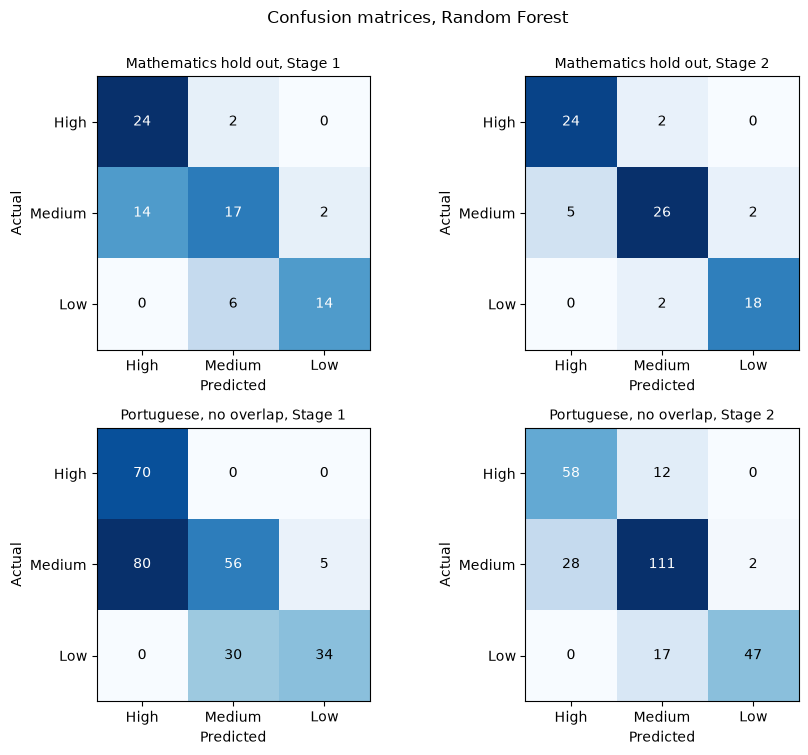

In [49]:
# ===== Confusion matrices, main model on both test sets and both stages =====
panels = [("Mathematics hold out", holdout), ("Portuguese, no overlap", por_clean)]
fig, axes = plt.subplots(2, 2, figsize=(9, 7.5))
long_rows = []

for r, (label, data) in enumerate(panels):
    for c, stage in enumerate(STAGE_COLS):
        pred = score_students(data[STAGE_COLS[stage]], bundles[MAIN_MODEL])["risk"].values
        matrix = confusion_matrix(data["risk"], pred, labels=RISK_ORDER)

        ax = axes[r, c]
        ax.imshow(matrix, cmap="Blues")
        for i in range(3):
            for j in range(3):
                ax.text(j, i, matrix[i, j], ha="center", va="center",
                        color="white" if matrix[i, j] > matrix.max() / 2 else "black")
                long_rows.append({"test set": label, "stage": stage, "true": RISK_ORDER[i],
                                  "predicted": RISK_ORDER[j], "students": int(matrix[i, j])})
        ax.set_xticks(range(3))
        ax.set_xticklabels(RISK_ORDER)
        ax.set_yticks(range(3))
        ax.set_yticklabels(RISK_ORDER)
        ax.set_xlabel("Predicted")
        ax.set_ylabel("Actual")
        ax.set_title(f"{label}, {STAGE_LABEL[stage]}", fontsize=10)

plt.suptitle(f"Confusion matrices, {MAIN_MODEL}", y=1.0)
plt.tight_layout()
plt.savefig(FIGURES / "confusion_matrices_rf.png", dpi=200)
plt.show()

pd.DataFrame(long_rows).to_csv(TABLES / "v2_confusion_counts_rf.csv", index=False)

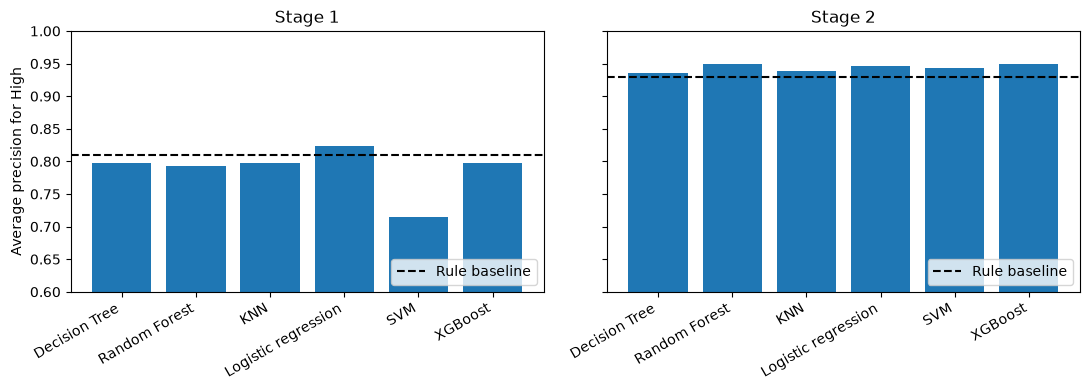

In [50]:
# ===== Development comparison chart, average precision for High =====
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)

for ax, stage in zip(axes, STAGE_COLS):
    part = (dev_six[(dev_six["stage"] == stage) & dev_six["model"].isin(MODEL_NAMES)]
            .set_index("model").loc[MODEL_NAMES])
    rule = dev_six[(dev_six["stage"] == stage) & dev_six["model"].str.startswith("Rule")]["avg_precision"].iloc[0]

    ax.bar(range(len(MODEL_NAMES)), part["avg_precision"])
    ax.axhline(rule, linestyle="--", color="black", label="Rule baseline")
    ax.set_xticks(range(len(MODEL_NAMES)))
    ax.set_xticklabels(MODEL_NAMES, rotation=30, ha="right")
    ax.set_title(STAGE_LABEL[stage])
    ax.set_ylim(0.6, 1.0)
    ax.legend(loc="lower right")

axes[0].set_ylabel("Average precision for High")
plt.tight_layout()
plt.savefig(FIGURES / "model_comparison_dev.png", dpi=200)
plt.show()

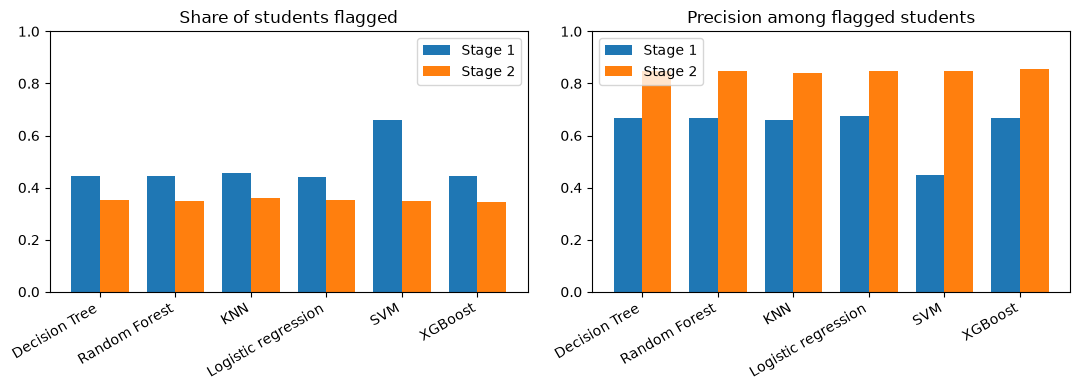

In [51]:
# ===== Stage 1 against Stage 2 trade off at the recall target =====
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
x = np.arange(len(MODEL_NAMES))
width = 0.38

for ax, column, title in [(axes[0], "share_flagged", "Share of students flagged"),
                          (axes[1], "precision", "Precision among flagged students")]:
    for offset, stage in [(-width / 2, "stage1"), (width / 2, "stage2")]:
        part = op[op["stage"] == stage].set_index("model").loc[MODEL_NAMES]
        ax.bar(x + offset, part[column], width, label=STAGE_LABEL[stage])
    ax.set_xticks(x)
    ax.set_xticklabels(MODEL_NAMES, rotation=30, ha="right")
    ax.set_title(title)
    ax.set_ylim(0, 1)
    ax.legend()

plt.tight_layout()
plt.savefig(FIGURES / "stage_tradeoff.png", dpi=200)
plt.show()

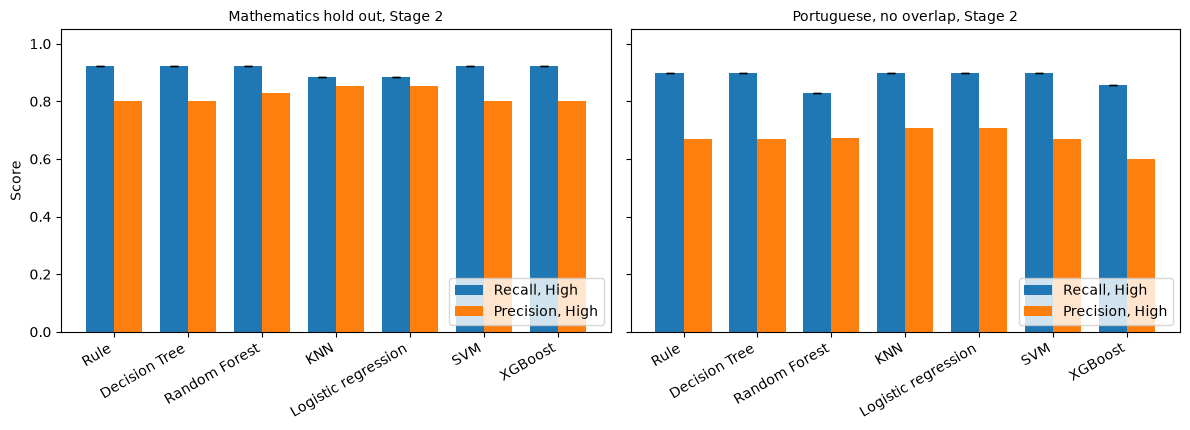

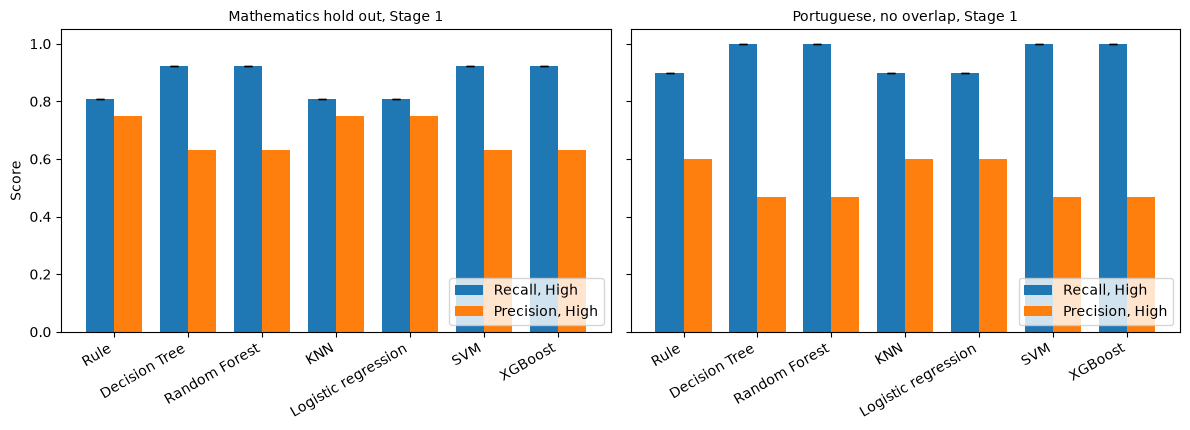

In [52]:
# ===== Recall and precision on the test sets =====
def plot_test_results(stage, filename):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), sharey=True)

    for ax, label in zip(axes, ["Mathematics hold out", "Portuguese, no overlap"]):
        part = detailed[(detailed["test set"] == label) & (detailed["stage"] == stage)].reset_index(drop=True)
        x = np.arange(len(part))
        width = 0.38
        err = np.clip(part["recall_high"] - part["recall_ci_low"],
                      part["recall_ci_high"] - part["recall_high"], 0, None)

        ax.bar(x - width / 2, part["recall_high"], width, yerr=err, capsize=3, label="Recall, High")
        ax.bar(x + width / 2, part["precision_high"], width, label="Precision, High")
        ax.set_xticks(x)
        ax.set_xticklabels(part["approach"].replace(r"^Rule.*", "Rule", regex=True),
                           rotation=30, ha="right")
        ax.set_title(f"{label}, {STAGE_LABEL[stage]}", fontsize=10)
        ax.set_ylim(0, 1.05)
        ax.legend(loc="lower right")

    axes[0].set_ylabel("Score")
    plt.tight_layout()
    plt.savefig(FIGURES / filename, dpi=200)
    plt.show()


plot_test_results("stage2", "test_recall_precision_stage2.png")
plot_test_results("stage1", "test_recall_precision_stage1.png")

,dataset,students,mean_G3_minus_G2,students_with_G2_8_or_9,of_which_reaching_10_or_more,share_reaching_10_or_more
0,"Mathematics, all",395,-0.299,82,24,0.293
1,"Portuguese, full file",649,0.336,112,56,0.500
2,"Portuguese, no overlap",275,0.411,66,31,0.470


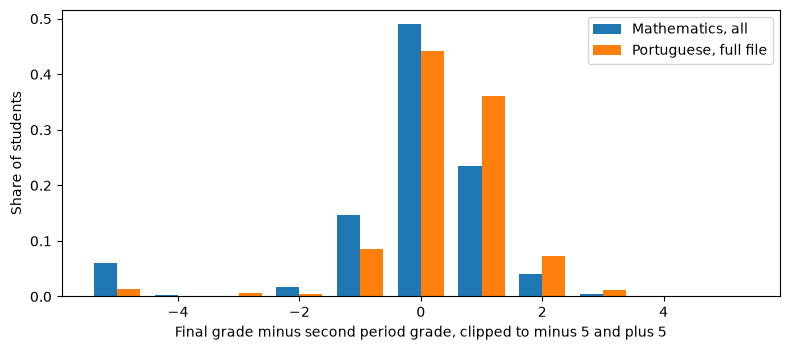

In [53]:
# ===== Change between G2 and the final grade =====
datasets = [("Mathematics, all", load_math()),
            ("Portuguese, full file", por_full),
            ("Portuguese, no overlap", por_clean)]

rows = []
for label, d in datasets:
    border = d[d["G2"].isin([8, 9])]
    rows.append({
        "dataset": label, "students": len(d),
        "mean_G3_minus_G2": (d["G3"] - d["G2"]).mean(),
        "students_with_G2_8_or_9": len(border),
        "of_which_reaching_10_or_more": int((border["G3"] >= 10).sum()),
        "share_reaching_10_or_more": (border["G3"] >= 10).mean(),
    })

drift = pd.DataFrame(rows).round(3)
drift.to_csv(TABLES / "v2_grade_drift.csv", index=False)
display(drift)

# ===== Chart of the change, clipped to minus 5 and plus 5 =====
fig, ax = plt.subplots(figsize=(8, 3.6))
values = list(range(-5, 6))
width = 0.38

for offset, (label, d) in [(-width / 2, datasets[0]), (width / 2, datasets[1])]:
    share = ((d["G3"] - d["G2"]).clip(-5, 5)
             .value_counts(normalize=True).reindex(values, fill_value=0))
    ax.bar(np.array(values) + offset, share.values, width, label=label)

ax.set_xlabel("Final grade minus second period grade, clipped to minus 5 and plus 5")
ax.set_ylabel("Share of students")
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES / "grade_drift.png", dpi=200)
plt.show()

In [54]:
# ===== Output check =====
expected = [
    "v2_dev_six_models.csv", "v2_bootstrap_gap.csv", "v2_dev_operating_points_six.csv",
    "v2_final_detailed_results.csv", "v2_confusion_counts_rf.csv", "v2_grade_drift.csv",
]
for name in expected:
    print("ok     " if (TABLES / name).exists() else "MISSING", name)

for name in ["v1_feature_sets.png", "confusion_matrices_rf.png", "model_comparison_dev.png",
             "stage_tradeoff.png", "test_recall_precision_stage2.png",
             "test_recall_precision_stage1.png", "grade_drift.png"]:
    print("ok     " if (FIGURES / name).exists() else "MISSING", name)

ok      v2_dev_six_models.csv
ok      v2_bootstrap_gap.csv
ok      v2_dev_operating_points_six.csv
ok      v2_final_detailed_results.csv
ok      v2_confusion_counts_rf.csv
ok      v2_grade_drift.csv
ok      v1_feature_sets.png
ok      confusion_matrices_rf.png
ok      model_comparison_dev.png
ok      stage_tradeoff.png
ok      test_recall_precision_stage2.png
ok      test_recall_precision_stage1.png
ok      grade_drift.png
